In [1]:
import sys
sys.path.insert(0, "../../lib") 
import neurality

import pandas as pd 
import numpy as np
from sklearn.preprocessing import OneHotEncoder

In [2]:
data = pd.read_csv("Titanic-Dataset.csv")
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
features = data.drop(["Survived", "Name", "Sex", "Ticket", "Fare", "Cabin"], axis=1)
features["Age"] = features["Age"].fillna(features["Age"].mean())
features["Embarked"] = features["Embarked"].fillna(features["Embarked"].mode().iloc[0])


encoder = OneHotEncoder(sparse_output=False)
encoded_data = encoder.fit_transform(features[["Embarked"]])
encoded_columns = encoder.get_feature_names_out()
features.isnull().sum()
encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoded_columns,
    index=features.index,
)
features = pd.concat(
    [features.drop(columns=["Embarked"]), encoded_df],
    axis=1,
)
features = features.drop(columns=["PassengerId"])

mean = features.mean()
std = features.std().replace(0, 1)
features = (features - mean) / std
features.head()



,Pclass,Age,SibSp,Parch,Embarked_C,Embarked_Q,Embarked_S
0,0.826913,-0.592148,0.432550,-0.473408,-0.481772,-0.30739,0.615493
1,-1.565228,0.638430,0.432550,-0.473408,2.073341,-0.30739,-1.622891
2,0.826913,-0.284503,-0.474279,-0.473408,-0.481772,-0.30739,0.615493
3,-1.565228,0.407697,0.432550,-0.473408,-0.481772,-0.30739,0.615493
4,0.826913,0.407697,-0.474279,-0.473408,-0.481772,-0.30739,0.615493


In [4]:
target = data[["Survived"]]
target = np.asarray(target, dtype=float).reshape(-1, 1)

In [ ]:
model = neurality.Neurality().fit(features, target)
model.backend(model.Backends.NUMPY) 
model.dense(8, 
                 activation_function=neurality.Neurality.Activations.tanh, 
                 derivative=neurality.Neurality.Derivations.deriv_tanh, bias=0,
                 initialization=model.Initializations.glorot)
model.dense(3, 
                 activation_function=neurality.Neurality.Activations.relu, 
                 derivative=neurality.Neurality.Derivations.deriv_relu, bias=0,
                 initialization=model.Initializations.kaiming)
model.dense(1, 
                 activation_function=neurality.Neurality.Activations.sigmoid, 
                 derivative=neurality.Neurality.Derivations.deriv_sigmoid, bias=0)

for x in range(1000):
    result = model.forward(features)
    loss = model.Loss.loss_bce(result, target) 
    print(f"epoch: {x}, loss: {loss}")
    model.backward(target, gradient_function=neurality.Neurality.Gradients.gradient_bce, learning_rate=0.9)



epoch: 0, loss: 0.6917997640039447
epoch: 1, loss: 0.6803876001908278
epoch: 2, loss: 0.665422511084149
epoch: 3, loss: 0.6538889593030611
epoch: 4, loss: 0.6471524068436266
epoch: 5, loss: 0.6428086238324514
epoch: 6, loss: 0.6383436192838898
epoch: 7, loss: 0.6315573628528628
epoch: 8, loss: 0.6184804043372111
epoch: 9, loss: 0.6004813010490643
epoch: 10, loss: 0.5892699378035661
epoch: 11, loss: 0.5901767039748042
epoch: 12, loss: 0.5967538317087947
epoch: 13, loss: 0.5961545082187055
epoch: 14, loss: 0.5899034308520066
epoch: 15, loss: 0.5837320478898727
epoch: 16, loss: 0.5794754341936823
epoch: 17, loss: 0.5770106122989387
epoch: 18, loss: 0.5754999776563542
epoch: 19, loss: 0.5743924967349819
epoch: 20, loss: 0.5733808469760349
epoch: 21, loss: 0.5716439722786014
epoch: 22, loss: 0.5700333014086861
epoch: 23, loss: 0.5684463897187221
epoch: 24, loss: 0.5659784401050024
epoch: 25, loss: 0.5631140900515145
epoch: 26, loss: 0.5603709653741095
epoch: 27, loss: 0.5581421540496834
epo

In [8]:
model.save("model.json")

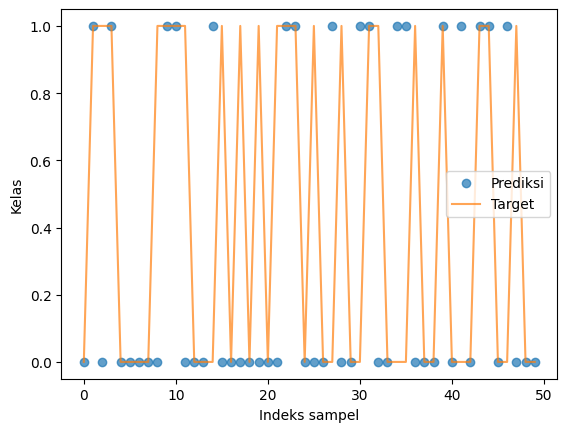

In [9]:
import matplotlib.pyplot as plt
prediction = model.forward(features).ravel()
actual = np.asarray(target).ravel()

plt.plot(prediction[:50] >= 0.5, label="Prediksi", alpha=0.7, linestyle='None',  marker='o')
plt.plot(actual[:50], label="Target", alpha=0.7)
plt.xlabel("Indeks sampel")
plt.ylabel("Kelas")
plt.legend()
plt.show()

In [10]:
prediction = (model.forward(features).ravel() >= 0.5).astype(int)
actual = np.asarray(target).ravel()

accuracy = np.mean(prediction == actual)
print(f"Accuracy: {accuracy:.2%}")

Accuracy: 77.33%
